In [5]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Define Fuzzy Variables

In [6]:
# Input 1: Temperature inside the room (°C)
room_temperature = ctrl.Antecedent(
    np.arange(0, 41, 1),
    'room_temperature'
)

# Input 2: Temperature outside the room (°C)
outside_temperature = ctrl.Antecedent(
    np.arange(-10, 41, 1),
    'outside_temperature'
)

# Output: Heater power (%)
heater_power = ctrl.Consequent(
    np.arange(0, 101, 1),
    'heater_power'
)

print("Fuzzy variables created successfully!")

Fuzzy variables created successfully!


## 3. Membership Functions

In [7]:
# Membership functions for room temperature
room_temperature['low'] = fuzz.trimf(
    room_temperature.universe, [0, 0, 20]
)

room_temperature['medium'] = fuzz.trimf(
    room_temperature.universe, [10, 22, 32]
)

room_temperature['high'] = fuzz.trimf(
    room_temperature.universe, [25, 40, 40]
)


# Membership functions for outside temperature
outside_temperature['low'] = fuzz.trimf(
    outside_temperature.universe, [-10, -10, 10]
)

outside_temperature['medium'] = fuzz.trimf(
    outside_temperature.universe, [0, 15, 30]
)

outside_temperature['high'] = fuzz.trimf(
    outside_temperature.universe, [20, 40, 40]
)


# Membership functions for heater power
heater_power['low'] = fuzz.trimf(
    heater_power.universe, [0, 0, 40]
)

heater_power['medium'] = fuzz.trimf(
    heater_power.universe, [20, 50, 80]
)

heater_power['high'] = fuzz.trimf(
    heater_power.universe, [60, 100, 100]
)

print("Membership functions created successfully!")

Membership functions created successfully!


c:\Users\Asus\Documents\Lab2_AI_Fuzzy_Temperature\.venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


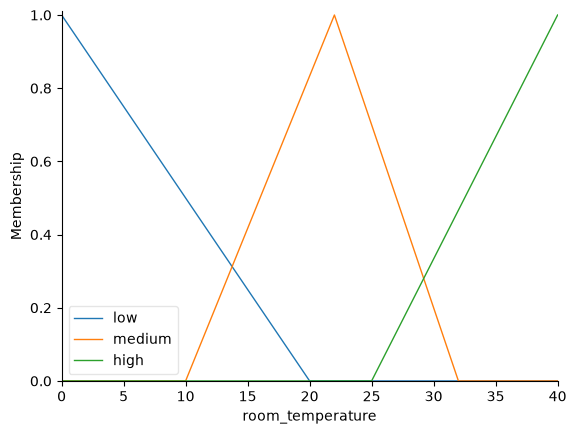

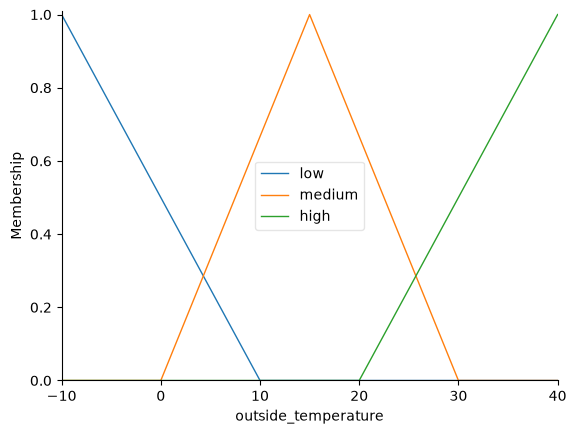

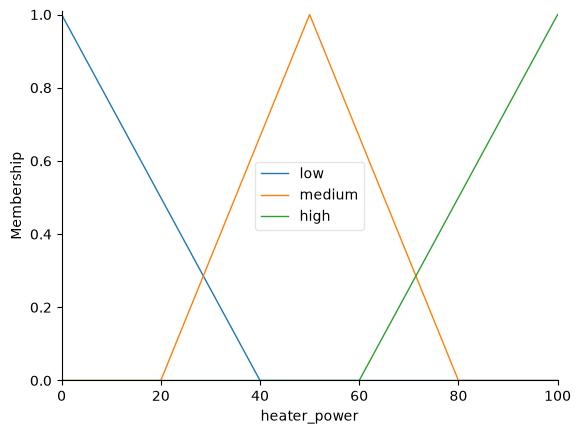

In [8]:
room_temperature.view()
plt.show()

outside_temperature.view()
plt.show()

heater_power.view()
plt.show()

## 4. Fuzzy Rules

In [9]:
# Rule 1: Cold room and cold outside
rule1 = ctrl.Rule(
    room_temperature['low'] & outside_temperature['low'],
    heater_power['high']
)

# Rule 2: Cold room and medium outside
rule2 = ctrl.Rule(
    room_temperature['low'] & outside_temperature['medium'],
    heater_power['high']
)

# Rule 3: Medium room temperature
rule3 = ctrl.Rule(
    room_temperature['medium'],
    heater_power['medium']
)

# Rule 4: Hot room temperature
rule4 = ctrl.Rule(
    room_temperature['high'],
    heater_power['low']
)

# Rule 5: Cold room and hot outside
rule5 = ctrl.Rule(
    room_temperature['low'] & outside_temperature['high'],
    heater_power['medium']
)

print("5 fuzzy rules created successfully!")

5 fuzzy rules created successfully!


In [10]:
# Combine all rules into one control system
temperature_control = ctrl.ControlSystem([
    rule1,
    rule2,
    rule3,
    rule4,
    rule5
])

# Create a simulation object
temperature_simulation = ctrl.ControlSystemSimulation(
    temperature_control
)

print("Fuzzy control system created successfully!")

Fuzzy control system created successfully!


## 5. Simulation and Testing

In [13]:
# Set input values
room_temp = 15
outside_temp = -5

temperature_simulation.input['room_temperature'] = room_temp
temperature_simulation.input['outside_temperature'] = outside_temp

# Run fuzzy inference
temperature_simulation.compute()

# Display the result
print("Room temperature:", room_temp, "°C")
print("Outside temperature:", outside_temp, "°C")
print(
    "Heater power:",
    round(temperature_simulation.output['heater_power'], 2),
    "%"
)

Room temperature: 15 °C
Outside temperature: -5 °C
Heater power: 58.78 %


In [14]:
test_cases = [
    (5, -5),
    (15, 10),
    (22, 20),
    (30, 25),
    (10, 35)
]

results = []

for room_temp, outside_temp in test_cases:
    temperature_simulation.input['room_temperature'] = room_temp
    temperature_simulation.input['outside_temperature'] = outside_temp

    temperature_simulation.compute()

    power = temperature_simulation.output['heater_power']

    results.append({
        'Room temperature (°C)': room_temp,
        'Outside temperature (°C)': outside_temp,
        'Heater power (%)': round(power, 2)
    })

for result in results:
    print(result)

{'Room temperature (°C)': 5, 'Outside temperature (°C)': -5, 'Heater power (%)': np.float64(86.0)}
{'Room temperature (°C)': 15, 'Outside temperature (°C)': 10, 'Heater power (%)': np.float64(58.78)}
{'Room temperature (°C)': 22, 'Outside temperature (°C)': 20, 'Heater power (%)': np.float64(50.0)}
{'Room temperature (°C)': 30, 'Outside temperature (°C)': 25, 'Heater power (%)': np.float64(33.7)}
{'Room temperature (°C)': 10, 'Outside temperature (°C)': 35, 'Heater power (%)': np.float64(50.0)}


## 6. Visualization of Simulation Results

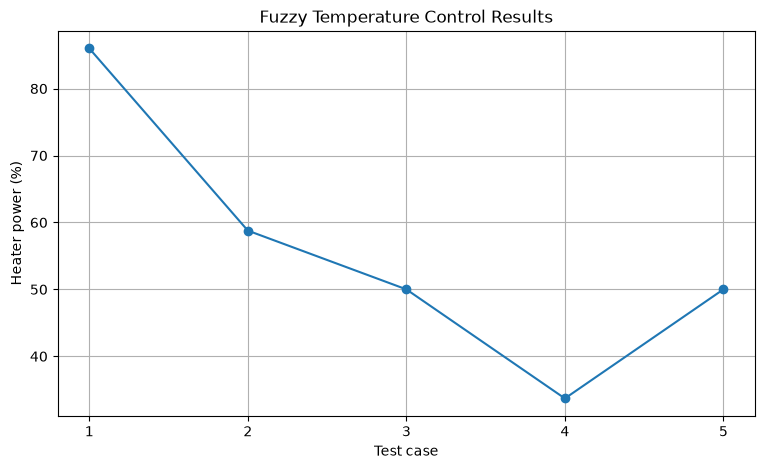

In [15]:
# Extract data from test results
room_temps = [r['Room temperature (°C)'] for r in results]
outside_temps = [r['Outside temperature (°C)'] for r in results]
heater_powers = [r['Heater power (%)'] for r in results]

# Plot heater power for each test case
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(results) + 1),
    heater_powers,
    marker='o'
)

plt.xticks(range(1, len(results) + 1))
plt.xlabel('Test case')
plt.ylabel('Heater power (%)')
plt.title('Fuzzy Temperature Control Results')
plt.grid(True)

plt.show()